# Melbourne House Prices - Modelling

**Goal:** predict a house's sale price from things a buyer would know: rooms, type, bathrooms, car spaces, land size, year built, suburb and distance to the CBD.

**Plan**
1. Clean the data, using the decisions from the EDA notebook
2. Split into training and test sets
3. Build a simple **baseline** (the suburb's median price) - every model has to beat this
4. Train **linear regression** and **XGBoost**
5. Compare them, check which features matter, and look at where the model goes wrong
6. Save the best model for the API

In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from pathlib import Path

from sklearn.model_selection import train_test_split, KFold
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, TargetEncoder
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error, r2_score
from sklearn.inspection import permutation_importance
from xgboost import XGBRegressor

sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", "{:,.2f}".format)

df = pd.read_csv("../data/raw/melb_data.csv")
print(df.shape)

(13580, 21)


## 1. Clean the data
These rules come straight from the EDA notebook:

| Problem | Fix | Why |
| --- | --- | --- |
| BuildingArea 47.5% missing | Drop the column | Too many blanks, weak link to price |
| Bedroom2 repeats Rooms 95% of the time | Drop the column | Duplicate information |
| Landsize = 0 for **houses** | Set to missing | A house always has land, so 0 is an error. For units it's real (shared land) |
| YearBuilt before 1850 | Set to missing | Almost certainly typos |

We also only keep columns a user could actually type into an app. `Method` and `SellerG` (the agent) aren't known before a sale, so they're out.

In [13]:
FEATURES_NUM = ["Rooms", "Bathroom", "Car", "Landsize", "YearBuilt", "Distance"]
FEATURES_CAT = ["Type", "Regionname"]
FEATURES_SUBURB = ["Suburb"]
FEATURES = FEATURES_NUM + FEATURES_CAT + FEATURES_SUBURB
TARGET = "Price"

def clean(data: pd.DataFrame) -> pd.DataFrame:
    data = data.copy()
    data.loc[(data["Landsize"] == 0) & (data["Type"] == "h"), "Landsize"] = np.nan
    data.loc[data["YearBuilt"] < 1850, "YearBuilt"] = np.nan
    return data[FEATURES + [TARGET]]

clean_df = clean(df)
print("Houses with Landsize set to missing:", ((df["Landsize"] == 0) & (df["Type"] == "h")).sum())
print("YearBuilt set to missing:", (df["YearBuilt"] < 1850).sum())
clean_df.isna().sum()

Houses with Landsize set to missing: 171
YearBuilt set to missing: 2


Rooms            0
Bathroom         0
Car             62
Landsize       171
YearBuilt     5377
Distance         0
Type             0
Regionname       0
Suburb           0
Price            0
dtype: int64

## 2. Split into train and test
We hide 20% of the sales from the model. After training, we test on those hidden sales.

**Analogy:** it's like studying from past exam papers and then sitting a paper you've never seen. If you only ever tested on the papers you studied, you'd think you were a genius - that's called **overfitting**.

In [14]:
X = clean_df[FEATURES]
y = clean_df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(f"Train: {len(X_train):,} sales | Test: {len(X_test):,} sales")

Train: 10,864 sales | Test: 2,716 sales


## 3. Baseline: just guess the suburb's median price
Before any machine learning, how good is a simple rule? If the fancy model can't beat this, it's not worth using.

In [15]:
results = {}

def score(name, y_true, y_pred):
    results[name] = {
        "MAE ($)": mean_absolute_error(y_true, y_pred),
        "MAPE (%)": mean_absolute_percentage_error(y_true, y_pred) * 100,
        "R2": r2_score(y_true, y_pred),
    }
    return pd.Series(results[name])

suburb_median = y_train.groupby(X_train["Suburb"]).median()
baseline_pred = X_test["Suburb"].map(suburb_median).fillna(y_train.median())
score("Baseline (suburb median)", y_test, baseline_pred)

MAE ($)    349,698.01
MAPE (%)        38.33
R2               0.28
dtype: float64

**How to read the scores**
- **MAE** (mean absolute error): on average, how many dollars the guess is off by. Lower is better.
- **MAPE**: the same thing as a percentage of the price. Lower is better.
- **R²**: how much of the price variation the model explains, from 0 (nothing) to 1 (everything). Higher is better.

## 4. The preprocessing pipeline
Models need numbers with no blanks, so every column goes through a few steps first:

- **Numbers:** fill blanks with the median, and add a yes/no column saying "this was blank" (sometimes *missing* is itself a clue)
- **Type and Region:** one-hot encoding - turn "h / t / u" into three yes/no columns
- **Suburb:** 314 different suburbs is too many for one-hot, so we use **target encoding** - replace each suburb with its typical price, learned only from the training data

We also train on **log(price)** like we decided in the EDA, then convert back to dollars. That stops a few $5M+ mansions from dominating.

Putting all this inside a `Pipeline` means the exact same steps run in training and later in the API - no copy-paste mistakes.

In [16]:
def make_preprocessor(scale_numbers: bool) -> ColumnTransformer:
    num_steps = [("impute", SimpleImputer(strategy="median", add_indicator=True))]
    if scale_numbers:
        num_steps.append(("scale", StandardScaler()))
    return ColumnTransformer([
        ("num", Pipeline(num_steps), FEATURES_NUM),
        ("cat", OneHotEncoder(handle_unknown="ignore"), FEATURES_CAT),
        ("suburb", TargetEncoder(cv=KFold(5, shuffle=True, random_state=42)), FEATURES_SUBURB),
    ])

def log_price_model(regressor, scale_numbers: bool):
    pipe = Pipeline([("prep", make_preprocessor(scale_numbers)), ("model", regressor)])
    return TransformedTargetRegressor(regressor=pipe, func=np.log, inverse_func=np.exp)

## 5. Model 1: Linear regression
Draws the best "straight line" through the data: each feature gets one weight, like "+X% per extra bathroom". Simple and easy to explain, but it can't learn curves or combinations (e.g. "land matters a lot for houses but not for units").

In [17]:
linear = log_price_model(Ridge(alpha=1.0), scale_numbers=True)
linear.fit(X_train, y_train)
score("Linear regression", y_test, linear.predict(X_test))

MAE ($)    266,360.84
MAPE (%)        22.11
R2             -13.32
dtype: float64

## 6. Model 2: XGBoost
Builds hundreds of small decision trees, one after another. Each new tree focuses on fixing the mistakes of the trees before it.

**Analogy:** a team of 500 junior valuers. The first gives a rough guess, the second only looks at where the first was wrong and corrects it, and so on. Together they're far better than any one of them. It can learn curves and combinations that linear regression can't.

In [18]:
xgb = log_price_model(
    XGBRegressor(n_estimators=600, learning_rate=0.05, max_depth=6,
                 subsample=0.8, colsample_bytree=0.8, random_state=42),
    scale_numbers=False,
)
xgb.fit(X_train, y_train)
score("XGBoost", y_test, xgb.predict(X_test))

MAE ($)    168,616.09
MAPE (%)        14.83
R2               0.81
dtype: float64

## 7. Compare the models

In [19]:
comparison = pd.DataFrame(results).T
base_mae = comparison.loc["Baseline (suburb median)", "MAE ($)"]
comparison["MAE vs baseline"] = (comparison["MAE ($)"] / base_mae - 1).map("{:+.0%}".format)
comparison

,MAE ($),MAPE (%),R2,MAE vs baseline
Baseline (suburb median),"349,698.01",38.33,0.28,+0%
Linear regression,"266,360.84",22.11,-13.32,-24%
XGBoost,"168,616.09",14.83,0.81,-52%


## 8. Which features matter most?
**Permutation importance:** shuffle one column at a time and see how much worse the model gets. If scrambling a column wrecks the predictions, the model relies on it heavily.

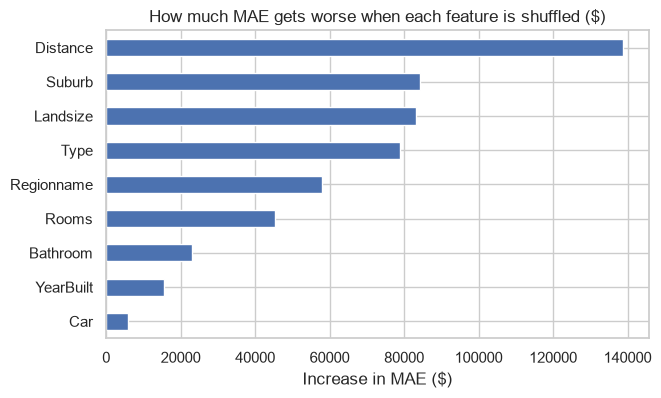

Distance      $138,737
Suburb         $84,334
Landsize       $83,196
Type           $78,772
Regionname     $57,927
Rooms          $45,427
Bathroom       $23,136
YearBuilt      $15,594
Car             $5,964
dtype: str

In [20]:
imp = permutation_importance(xgb, X_test, y_test, n_repeats=5, random_state=42,
                             scoring="neg_mean_absolute_error")
importance = pd.Series(imp.importances_mean, index=FEATURES).sort_values()

importance.plot(kind="barh", figsize=(7, 4),
                title="How much MAE gets worse when each feature is shuffled ($)")
plt.xlabel("Increase in MAE ($)")
plt.show()
importance.sort_values(ascending=False).map("${:,.0f}".format)

## 9. Where does the model go wrong?

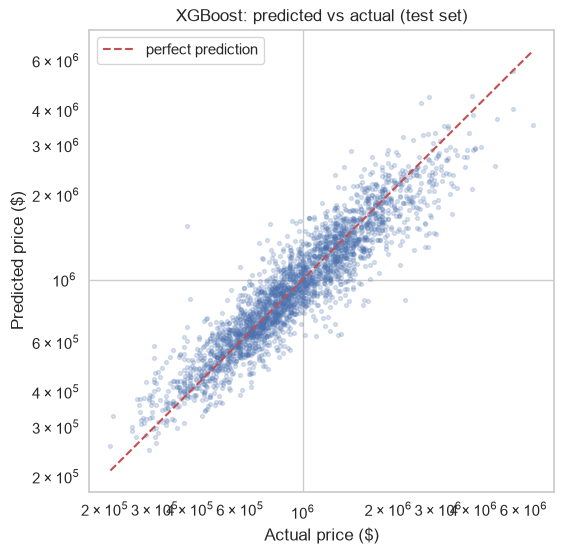

Median % error by property type:
Type
h   11.80
t    9.90
u   11.00
Name: pct_error, dtype: float64

Median % error by price band:
actual
cheapest 25%   11.10
2nd             9.80
3rd            11.40
priciest 25%   14.30
Name: pct_error, dtype: float64


In [21]:
pred = xgb.predict(X_test)
errors = X_test.assign(actual=y_test, predicted=pred,
                       pct_error=(pred - y_test).abs() / y_test * 100)

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(errors["actual"], errors["predicted"], alpha=0.2, s=8)
lims = [errors[["actual", "predicted"]].min().min(), errors[["actual", "predicted"]].max().max()]
ax.plot(lims, lims, "r--", label="perfect prediction")
ax.set(xscale="log", yscale="log", xlabel="Actual price ($)", ylabel="Predicted price ($)",
       title="XGBoost: predicted vs actual (test set)")
ax.legend()
plt.show()

print("Median % error by property type:")
print(errors.groupby("Type")["pct_error"].median().round(1))
print("\nMedian % error by price band:")
bands = pd.qcut(errors["actual"], 4, labels=["cheapest 25%", "2nd", "3rd", "priciest 25%"])
print(errors.groupby(bands, observed=True)["pct_error"].median().round(1))

## 10. Save the model for the API
We retrain on **all** the data (more data = slightly better model) and save the whole pipeline, cleaning included, as one file.

In [22]:
final_model = log_price_model(
    XGBRegressor(n_estimators=600, learning_rate=0.05, max_depth=6,
                 subsample=0.8, colsample_bytree=0.8, random_state=42),
    scale_numbers=False,
)
final_model.fit(X, y)

Path("../models").mkdir(exist_ok=True)
joblib.dump({"model": final_model, "features": FEATURES}, "../models/house_price_model.joblib")
print("Saved models/house_price_model.joblib")

# quick sanity check with a made-up house
example = pd.DataFrame([{
    "Rooms": 3, "Bathroom": 2, "Car": 1, "Landsize": 450, "YearBuilt": 1990,
    "Distance": 10.0, "Type": "h", "Regionname": "Southern Metropolitan", "Suburb": "Brighton East",
}])
print(f"Example 3-bed house in Brighton East: ${final_model.predict(example)[0]:,.0f}")

Saved models/house_price_model.joblib
Example 3-bed house in Brighton East: $891,134


## Results
- **Best model:** XGBoost, trained on log(price)
- **Test MAE:** $168,616 - 52% lower than the suburb-median baseline ($349,698)
- **Typical error:** 14.8% MAPE (median error per home about 11-12%), R² = 0.81
- **Top features:** Distance to CBD, Suburb, Land size, Property type. Distance looked weak in the EDA (correlation -0.16), but its effect is curved, which XGBoost captures and a straight line can't.
- **Where it struggles:** the priciest 25% of homes (14.3% error). It under-prices $3M+ homes, which are rare in the data and often get their value from features not recorded (views, renovations).
- **Linear regression** beat the baseline on MAE (-24%) but produced a few extreme predictions (R² -13), showing how linear models extrapolate badly on unusual inputs.